# Mix-Head Self-Attention Causal Host Architecture (DARPA OpTC)
### Full-Corpus Training — Accelerated on Kaggle Dual GPU (NVIDIA Tesla T4 x 2)

**Pipeline thay đổi so với phiên bản cũ:**
- **Trước:** stream raw JSON (50k cap) -> tokenise on-the-fly -> auto-build vocab -> train
- **Bây giờ:** load pre-built shards (toàn bộ 8,331,257 events từ Contextual Split Seed 02: 6.25M Train, 833k Val, 1.25M Test) -> train trực tiếp trên Dual GPU T4x2 (không tốn CPU tokenise lại)

**Pre-requisite:** Shards đã được tạo chuẩn bằng `build_dl_shards_from_contextual_split.py` và đóng gói trong dataset Kaggle (`dl-optc`).


In [1]:
# ── Cell 1: Hardware & Dual GPU Audit ──────────────────────────────────────
import os, sys, torch

print('=== HARDWARE & GPU AUDIT ===')
print(f'PyTorch Version : {torch.__version__}')
print(f'CUDA Available  : {torch.cuda.is_available()}')
num_gpus = torch.cuda.device_count()
print(f'GPU Count       : {num_gpus}')

if num_gpus >= 2:
    for i in range(num_gpus):
        props = torch.cuda.get_device_properties(i)
        print(f'  [GPU {i}] {props.name} | VRAM: {props.total_memory / (1024**3):.2f} GB')
    print('SUCCESS: Dual T4 GPUs detected — DDP mode.')
elif num_gpus == 1:
    props = torch.cuda.get_device_properties(0)
    print(f'  [GPU 0] {props.name} | VRAM: {props.total_memory / (1024**3):.2f} GB')
    print('NOTE: Single GPU.')
else:
    print('WARNING: No GPU — CPU mode.')

=== HARDWARE & GPU AUDIT ===
PyTorch Version : 2.11.0+cu130
CUDA Available  : True
GPU Count       : 2
  [GPU 0] Tesla T4 | VRAM: 14.56 GB
  [GPU 1] Tesla T4 | VRAM: 14.56 GB
SUCCESS: Dual T4 GPUs detected — DDP mode.


In [2]:
# ── Cell 2: Resolve Paths ───────────────────────────────────────────────────
import json
import os
import sys
from pathlib import Path

# ── Candidate package dirs ──
possible_pkg_dirs = [
    Path("/kaggle/input/datasets/ngkimngn/dl-optc/causal_bilstm_pkg"),
    Path("/kaggle/input/dl-optc/causal_bilstm_pkg"),
    Path("/mnt/SSD_Data/optc/DL/code/preprocess"),
]
pkg_dir = next((p for p in possible_pkg_dirs if p.exists() and (p / "label_catalog.py").exists()), None)
if pkg_dir is None and Path("/kaggle/input").exists():
    for p in Path("/kaggle/input").rglob("label_catalog.py"):
        pkg_dir = p.parent
        break

if pkg_dir and str(pkg_dir) not in sys.path:
    sys.path.insert(0, str(pkg_dir))

# ── Candidate data dirs ──
possible_data_dirs = [
    Path("/kaggle/input/datasets/ngkimngn/dl-optc/data"),
    Path("/kaggle/input/dl-optc/data"),
    Path("/mnt/SSD_Data/optc/DL/code/others"),
]
data_dir = next((p for p in possible_data_dirs if p.exists()), None)
if data_dir is None and Path("/kaggle/input").exists():
    for p in Path("/kaggle/input").rglob("dl_vocab.json"):
        data_dir = p.parent
        break

# ── Candidate SHARDS dirs ──
# Shards are uploaded as a separate dataset or sub-folder in the same dataset
possible_shard_dirs = [
    Path("/kaggle/input/datasets/ngkimngn/dl-optc/dl_shards"),
    Path("/kaggle/input/dl-optc-shards/dl_shards"),
    Path("/kaggle/input/dl-optc/dl_shards"),
    Path("/kaggle/input/dl-optc"),
    Path("/mnt/SSD_Data/optc/DL/code/output/dl_shards"),
]
shards_dir = next((p for p in possible_shard_dirs if (p / "split_manifest.json").exists()), None)
if shards_dir is None and Path("/kaggle/input").exists():
    for p in Path("/kaggle/input").rglob("split_manifest.json"):
        shards_dir = p.parent
        break

# ── Resolve vocab (needed for eval only) ──
vocab_path = None
if data_dir:
    for name in ["dl_vocab.json"]:
        p = data_dir / name
        if p.exists():
            vocab_path = p
            break

# ── Resolve labels (needed for eval reporting) ──
labels_path = None
if data_dir:
    for name in ["optc_multitask_labels_v1.json.gz", "optc_multitask_labels_v1.json"]:
        p = data_dir / name
        if p.exists():
            labels_path = p
            break

print(f"pkg_dir    : {pkg_dir}")
print(f"data_dir   : {data_dir}")
print(f"shards_dir : {shards_dir}")
print(f"vocab_path : {vocab_path}")
print(f"labels_path: {labels_path}")

if shards_dir is None:
    raise FileNotFoundError(
        "CRITICAL: dl_shards/ not found!\n"
        "Run build_dl_shards_from_contextual_split.py locally first, then upload the output to Kaggle dataset ngkimngn/dl-optc."
    )

# Read manifest for sanity check
with (shards_dir / "split_manifest.json").open() as f:
    manifest = json.load(f)
print()
print("=== SHARD MANIFEST ===")
print(f"  Total samples : {manifest.get('total_samples', 0):,}")
split_map = manifest.get("split") or manifest.get("split_summary", {})
for split, info in split_map.items():
    print(f"  [{split}] {info.get('n_samples', 0):,} samples | {len(info.get('shards', []))} shards")
print(f"  Vocab size    : {manifest.get('vocab', {}).get('vocab_size', 0):,}")
print(f"  Split seed    : {manifest.get('seed')}")


pkg_dir    : /kaggle/input/datasets/ngkimngn/dl-optc/causal_bilstm_pkg
data_dir   : /kaggle/input/datasets/ngkimngn/dl-optc/data
shards_dir : /kaggle/input/datasets/ngkimngn/dl-optc/dl_shards
vocab_path : /kaggle/input/datasets/ngkimngn/dl-optc/data/dl_vocab.json
labels_path: /kaggle/input/datasets/ngkimngn/dl-optc/data/optc_multitask_labels_v1.json

=== SHARD MANIFEST ===
  Total samples : 8,331,257
  [train] 6,248,443 samples | 625 shards
  [val] 833,125 samples | 84 shards
  [test] 1,249,689 samples | 125 shards
  Vocab size    : 10,499
  Split seed    : 2


In [3]:
# ── Cell 3: Full-Corpus Training via torchrun (Mix-Head, Shard Mode) ────────
train_script = None
script_candidates = [
    (pkg_dir / "train_mixhead_attention.py") if pkg_dir else None,
    Path("/kaggle/input/datasets/ngkimngn/dl-optc/causal_bilstm_pkg/train_mixhead_attention.py"),
    Path("/mnt/SSD_Data/optc/DL/code/preprocess/train_mixhead_attention.py"),
]
for cand in script_candidates:
    if cand and cand.exists():
        train_script = cand
        break

if train_script is None and Path("/kaggle/input").exists():
    for p in Path("/kaggle/input").rglob("train_mixhead_attention.py"):
        train_script = p
        break

if train_script is None:
    raise FileNotFoundError("Could not find train_mixhead_attention.py!")

output_model_path = (
    "/kaggle/working/mixhead_attention_t4x2_full.pt"
    if Path("/kaggle/working").exists()
    else "/mnt/SSD_Data/optc/DL/code/output/mixhead_attention_multitask.pt"
)

cmd = f"""torchrun --nproc_per_node={max(num_gpus, 1)} {train_script} \n    --shards-dir {shards_dir} \n    --epochs 10 \n    --batch-size 256 \n    --lr 0.001 \n    --embed-dim 128 \n    --num-heads 4 \n    --blocks 2 \n    --output-model {output_model_path}"""

print(f"Executing Mix-Head Full-Corpus Command:\n{cmd}")
!{cmd}


Executing Mix-Head Full-Corpus Command:
torchrun --nproc_per_node=2 /kaggle/input/datasets/ngkimngn/dl-optc/causal_bilstm_pkg/train_mixhead_attention.py     --shards-dir /kaggle/input/datasets/ngkimngn/dl-optc/dl_shards     --epochs 10     --batch-size 256     --lr 0.001     --embed-dim 128     --num-heads 4     --blocks 2     --output-model /kaggle/working/mixhead_attention_t4x2_full.pt
W1124 07:30:07.973000 45 torch/distributed/run.py:851] 
W1124 07:30:07.973000 45 torch/distributed/run.py:851] *****************************************
W1124 07:30:07.973000 45 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1124 07:30:07.973000 45 torch/distributed/run.py:851] *****************************************
[2026-11-24 07:30:14] [INFO] Initializing Mix-Head Self-Attention Training (World: 2, Local Ra

In [4]:
# ── Cell 4: Full Evaluation — load vocab from checkpoint (no mismatch) ──────
from sklearn.metrics import classification_report
from torch.utils.data import DataLoader
from label_catalog import MultiTaskLabelCatalog, SCENARIO_MAP, STAGE_MAP
from causal_dataset import TokenVocabulary, collate_causal_batch
from model_mixhead_attention import MixHeadSelfAttentionCausalHost

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Resolve checkpoint path
candidate_ckpts = [
    Path(output_model_path),
    Path("/kaggle/working/mixhead_attention_t4x2_full.pt"),
    Path("/kaggle/input/datasets/ngkimngn/dl-optc/mixhead_attention_multitask.pt"),
    Path("/kaggle/input/dl-optc/mixhead_attention_multitask.pt"),
    Path("/mnt/SSD_Data/optc/DL/code/output/mixhead_attention_multitask.pt"),
]
ckpt_file = next((p for p in candidate_ckpts if p.exists()), None)
if ckpt_file is None:
    raise FileNotFoundError(f"Checkpoint not found at {output_model_path}! Run Cell 3 to train first.")

# Load checkpoint
ckpt = torch.load(ckpt_file, map_location=device)
arch = ckpt["arch"]
model_vocab_size = ckpt["model_vocab_size"]   # exact embedding rows — no mismatch
print(f"Checkpoint loaded from: {ckpt_file}")
print(f"Checkpoint: epoch={ckpt['epoch']}  vocab_size={ckpt['vocab_size']:,}  model_vocab_size={model_vocab_size:,}")
print(f"Data mode : {ckpt.get('data_mode', 'unknown')}")

# Rebuild model from checkpoint arch params
model = MixHeadSelfAttentionCausalHost(
    vocab_size=model_vocab_size,
    embed_dim=arch["embed_dim"],
    num_heads=arch["num_heads"],
    ff_dim=arch["ff_dim"],
    num_transformer_blocks=arch["num_transformer_blocks"],
    num_scenarios=arch["num_scenarios"],
    num_stages=arch["num_stages"],
    enable_il_adapter=arch["enable_il_adapter"],
).to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()
print("Model loaded OK.")

# Load test shard dataset
from train_mixhead_attention import ShardDataset
split_map = manifest.get("split") or manifest.get("split_summary", {})
test_shards = [shards_dir / rel for rel in split_map["test"]["shards"]]
test_ds     = ShardDataset(test_shards)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, collate_fn=collate_causal_batch)
print(f"Test samples: {len(test_ds):,}")

y_bin_true, y_bin_pred = [], []
y_sc_true,  y_sc_pred  = [], []
y_st_true,  y_st_pred  = [], []
all_attn_maps = []

with torch.no_grad():
    for batch in test_loader:
        token_ids = batch["token_ids"].to(device)
        offsets   = batch["offsets"].to(device)
        bs        = batch["batch_size"]
        out       = model(token_ids, offsets, bs)

        bin_p = (torch.sigmoid(out["binary_logits"]).cpu().numpy() >= 0.5).astype(int)
        sc_p  = torch.argmax(out["scenario_logits"], dim=-1).cpu().numpy()
        st_p  = torch.argmax(out["stage_logits"],    dim=-1).cpu().numpy()

        y_bin_true.extend(batch["target_binary"].numpy())
        y_bin_pred.extend(bin_p)
        y_sc_true.extend(batch["target_scenario"].numpy())
        y_sc_pred.extend(sc_p)
        y_st_true.extend(batch["target_stage"].numpy())
        y_st_pred.extend(st_p)
        if len(all_attn_maps) < 5:
            all_attn_maps.append(out["attention_maps"][0].cpu())

print("\n=================== HEAD 1: BINARY DETECTION ===================")
print(classification_report(y_bin_true, y_bin_pred, target_names=["Benign", "Malicious"], digits=4))

sc_names = [SCENARIO_MAP[i] for i in range(4)]
print("================ HEAD 2: SCENARIO ATTRIBUTION ==================")
print(classification_report(y_sc_true, y_sc_pred, target_names=sc_names, digits=4))

unique_stages = sorted(set(y_st_true) | set(y_st_pred))
st_names = [STAGE_MAP[i] for i in unique_stages]
print("================ HEAD 3: MITRE ATT&CK TACTICS ==================")
print(classification_report(y_st_true, y_st_pred, labels=unique_stages, target_names=st_names, digits=4))


Checkpoint: epoch=10  vocab_size=10,499  model_vocab_size=10,599
Data mode : shards
Model loaded OK.
Test samples: 1,249,689

=================== HEAD 1: BINARY DETECTION ===================
              precision    recall  f1-score   support

      Benign     0.9998    1.0000    0.9999   1209379
   Malicious     0.9986    0.9950    0.9968     40310

    accuracy                         0.9998   1249689
   macro avg     0.9992    0.9975    0.9984   1249689
weighted avg     0.9998    0.9998    0.9998   1249689

================ HEAD 2: SCENARIO ATTRIBUTION ==================
                         precision    recall  f1-score   support

                 Benign     0.9998    1.0000    0.9999   1209379
      SC1_EmpireStaging     0.9974    0.9922    0.9948     14568
SC2_CustomEmpireLateral     0.9995    0.9969    0.9982     21665
    SC3_MaliciousUpdate     0.9980    0.9953    0.9967      4077

               accuracy                         0.9998   1249689
              macro avg  

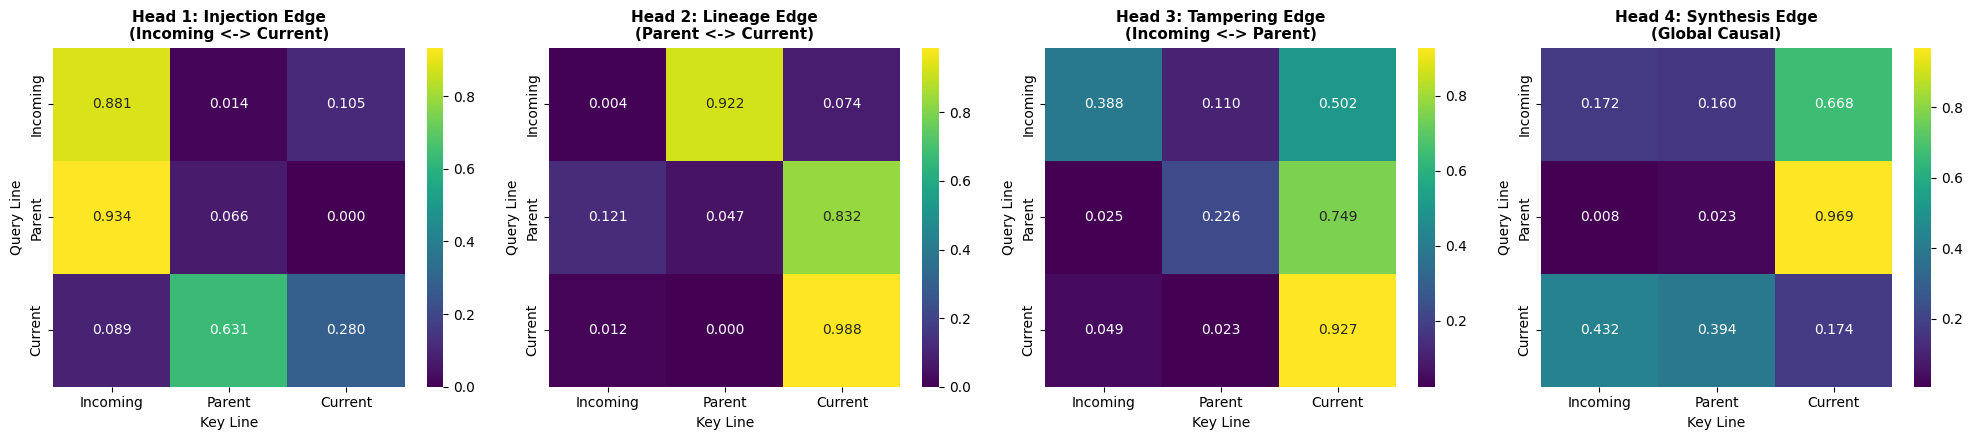

Saved attention heatmap → /kaggle/working/mixhead_attention_maps.png


In [5]:
# ── Cell 5: Causal Attention Heatmap Visualization ──────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

attn_batch = all_attn_maps[0].numpy().mean(axis=0)  # (4, 3, 3)
line_labels = ['Incoming', 'Parent', 'Current']
head_titles = [
    'Head 1: Injection Edge\n(Incoming <-> Current)',
    'Head 2: Lineage Edge\n(Parent <-> Current)',
    'Head 3: Tampering Edge\n(Incoming <-> Parent)',
    'Head 4: Synthesis Edge\n(Global Causal)',
]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for h in range(4):
    sns.heatmap(
        attn_batch[h], annot=True, fmt='.3f', cmap='viridis',
        xticklabels=line_labels, yticklabels=line_labels, ax=axes[h]
    )
    axes[h].set_title(head_titles[h], fontsize=11, fontweight='bold')
    axes[h].set_ylabel('Query Line')
    axes[h].set_xlabel('Key Line')

plt.tight_layout()
out_fig = (
    '/kaggle/working/mixhead_attention_maps.png'
    if Path('/kaggle/working').exists()
    else '/mnt/SSD_Data/optc/DL/code/output/mixhead_attention_maps.png'
)
plt.savefig(out_fig, dpi=300)
plt.show()
print(f'Saved attention heatmap → {out_fig}')

In [6]:
# ── Cell 6: Incremental Learning (IL) Freeze Verification ───────────────────
print('=== INCREMENTAL LEARNING (IL) ADAPTER VERIFICATION ===')
print(f'Total params: {sum(p.numel() for p in model.parameters()):,}')

model.freeze_base_for_il()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f'Trainable for new IL domain: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)')
print('Base Transformer FROZEN — only IL Adapter + Heads will train on new scenarios.')

=== INCREMENTAL LEARNING (IL) ADAPTER VERIFICATION ===
Total params: 1,680,560
Base Transformer backbone FROZEN for Incremental Learning.
Trainable for new IL domain: 59,312 / 1,680,560 (3.53%)
Base Transformer FROZEN — only IL Adapter + Heads will train on new scenarios.
